In [ ]:
!git clone https://github.com/jasmindamia/UTP-MACHINE-LEARNING.git /content/UTP-MACHINE-LEARNING

Cloning into '/content/UTP-MACHINE-LEARNING'...
remote: Enumerating objects: 53, done.
remote: Counting objects: 100% (53/53), done.
remote: Compressing objects: 100% (48/48), done.
remote: Total 53 (delta 17), reused 24 (delta 3), pack-reused 0 (from 0)
Receiving objects: 100% (53/53), 2.61 MiB | 6.17 MiB/s, done.
Resolving deltas: 100% (17/17), done.


In [ ]:

%cd /content/UTP-MACHINE-LEARNING

from pathlib import Path

PROJECT_ROOT = Path.cwd()
DATA = PROJECT_ROOT / "all_datasets"

print("Project root:", PROJECT_ROOT)
print("\nRepository contents:")
for item in sorted(PROJECT_ROOT.iterdir()):
    print(item.name)

print("\nChecking Lab 5 datasets:")
for filename in [
    "credit_card_fraud_dataset.csv",
    "breast_cancer_dataset.csv"
]:
    path = DATA / filename
    print(f"{filename}: {'FOUND' if path.exists() else 'NOT FOUND'}")


/content/UTP-MACHINE-LEARNING
Project root: /content/UTP-MACHINE-LEARNING

Repository contents:
.DS_Store
.git
.gitignore
all_datasets
all_experiments
models
results

Checking Lab 5 datasets:
credit_card_fraud_dataset.csv: FOUND
breast_cancer_dataset.csv: FOUND


In [4]:

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.ensemble import IsolationForest
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.semi_supervised import SelfTrainingClassifier

PROJECT_ROOT = Path.cwd()
DATA = PROJECT_ROOT / "all_datasets"

# Load both datasets
fraud = pd.read_csv(DATA / "credit_card_fraud_dataset.csv")
cancer = pd.read_csv(DATA / "breast_cancer_dataset.csv")

print("Fraud dataset shape:", fraud.shape)
print("Breast cancer dataset shape:", cancer.shape)

print("\nFraud dataset columns:")
print(fraud.columns.tolist())

print("\nBreast cancer dataset columns:")
print(cancer.columns.tolist())

print("\nFraud label distribution:")
print(fraud["is_fraud"].value_counts())
print("Fraud prevalence:", round(fraud["is_fraud"].mean() * 100, 2), "%")

print("\nBreast cancer diagnosis distribution:")
print(cancer["diagnosis"].value_counts())


Fraud dataset shape: (10000, 10)
Breast cancer dataset shape: (569, 33)

Fraud dataset columns:
['transaction_id', 'amount', 'transaction_hour', 'merchant_category', 'foreign_transaction', 'location_mismatch', 'device_trust_score', 'velocity_last_24h', 'cardholder_age', 'is_fraud']

Breast cancer dataset columns:
['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32']

Fraud label distribution:
is_fraud
0    9849
1     151
Name: count, dtype: int64
Fraud prevalence: 1.51 

In [5]:

# Select the seven features specified in the course notes
feature_cols = [
    "amount",
    "transaction_hour",
    "foreign_transaction",
    "location_mismatch",
    "device_trust_score",
    "velocity_last_24h",
    "cardholder_age",
]

X = fraud[feature_cols]
y = fraud["is_fraud"]

# Split data while preserving the fraud/non-fraud ratio
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y,
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Fraud cases in training labels:", int(y_train.sum()))
print("Fraud cases in test labels:", int(y_test.sum()))

# Fit Isolation Forest WITHOUT passing fraud labels
forest = IsolationForest(
    n_estimators=300,
    contamination="auto",
    random_state=42,
    n_jobs=-1,
)

forest.fit(X_train)

# Higher scores indicate more unusual transactions
anomaly_score = -forest.decision_function(X_test)

print("\nIsolation Forest training completed.")
print("Number of test scores:", len(anomaly_score))
print("Minimum anomaly score:", round(anomaly_score.min(), 4))
print("Maximum anomaly score:", round(anomaly_score.max(), 4))


Training samples: 7000
Testing samples: 3000
Fraud cases in training labels: 106
Fraud cases in test labels: 45

Isolation Forest training completed.
Number of test scores: 3000
Minimum anomaly score: -0.1005
Maximum anomaly score: 0.2129


In [6]:

# Evaluate anomaly scores using the held-back test labels
prevalence = y_test.mean()

ap = average_precision_score(y_test, anomaly_score)
auc = roc_auc_score(y_test, anomaly_score)

print("Fraud prevalence:", round(prevalence, 4))
print("ROC AUC:", round(auc, 4))
print(
    "Average precision:", round(ap, 4),
    f"({ap / prevalence:.1f}x prevalence)"
)

# Rank transactions from most to least anomalous
ranked = X_test.copy()
ranked["fraud_label"] = y_test.to_numpy()
ranked["anomaly_score"] = anomaly_score

ranked = ranked.sort_values(
    "anomaly_score",
    ascending=False,
)

# Evaluate the top 100 alerts
review_budget = 100
top_k_precision = ranked.head(review_budget)["fraud_label"].mean()

print(
    f"Fraud found in the top {review_budget}: "
    f"{top_k_precision:.1%}"
)

print("\nTop 10 highest-ranked transactions:")
print(
    ranked[
        ["fraud_label", "anomaly_score", "amount"]
    ].head(10)
)


Fraud prevalence: 0.015
ROC AUC: 0.9518
Average precision: 0.2249 (15.0x prevalence)
Fraud found in the top 100: 20.0%

Top 10 highest-ranked transactions:
      fraud_label  anomaly_score  amount
6394            0       0.212892  840.89
5883            0       0.168657  978.56
1623            1       0.166446  569.02
522             0       0.165520  630.67
5536            1       0.163377   28.31
9073            0       0.158442  131.05
4642            0       0.155478  351.99
645             1       0.155063  398.17
7166            0       0.154388  353.58
7698            0       0.152780   75.88


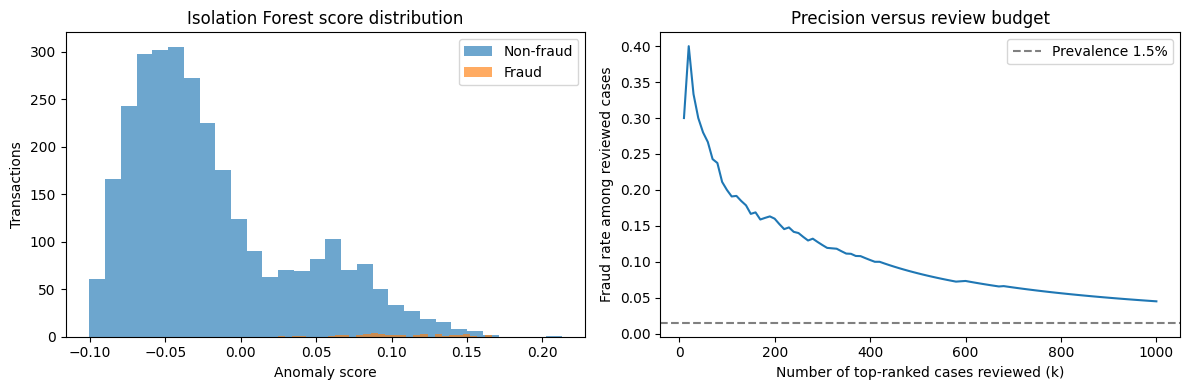

In [7]:

# Extract the test labels in the same order as anomaly_score
test_labels = y_test.to_numpy()

# Precision among the top k ranked transactions
hits = ranked["fraud_label"].to_numpy()
k_values = np.arange(10, 1001, 10)
precision_at_k = [
    hits[:k].mean() for k in k_values
]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Plot 1: Score overlap between fraud and non-fraud
axes[0].hist(
    anomaly_score[test_labels == 0],
    bins=30,
    alpha=0.65,
    label="Non-fraud",
)
axes[0].hist(
    anomaly_score[test_labels == 1],
    bins=30,
    alpha=0.65,
    label="Fraud",
)
axes[0].set_xlabel("Anomaly score")
axes[0].set_ylabel("Transactions")
axes[0].set_title("Isolation Forest score distribution")
axes[0].legend()

# Plot 2: Precision at different review budgets
axes[1].plot(k_values, precision_at_k)
axes[1].axhline(
    prevalence,
    linestyle="--",
    color="grey",
    label=f"Prevalence {prevalence:.1%}",
)
axes[1].set_xlabel("Number of top-ranked cases reviewed (k)")
axes[1].set_ylabel("Fraud rate among reviewed cases")
axes[1].set_title("Precision versus review budget")
axes[1].legend()

plt.tight_layout()
plt.show()


In [8]:

for budget in [50, 100, 300]:
    precision = ranked.head(budget)["fraud_label"].mean()
    fraud_found = int(ranked.head(budget)["fraud_label"].sum())

    print(
        f"Budget: {budget:3d} | "
        f"Fraud found: {fraud_found:2d} | "
        f"Precision: {precision:.1%}"
    )


Budget:  50 | Fraud found: 14 | Precision: 28.0%
Budget: 100 | Fraud found: 20 | Precision: 20.0%
Budget: 300 | Fraud found: 37 | Precision: 12.3%


In [9]:

# Reproducible random generator
rng = np.random.default_rng(42)

# Prepare features and binary diagnosis labels
cancer = pd.read_csv(DATA / "breast_cancer_dataset.csv")

X_c = cancer.drop(
    columns=["id", "diagnosis", "Unnamed: 32"],
    errors="ignore",
)

y_c = (cancer["diagnosis"] == "M").astype(int).to_numpy()

# Reserve a sealed test set
X_dev, Xc_test, y_dev, yc_test = train_test_split(
    X_c,
    y_c,
    test_size=0.25,
    random_state=42,
    stratify=y_c,
)

# Split the development data into query pool and validation set
X_pool, X_val, y_pool, y_val = train_test_split(
    X_dev,
    y_dev,
    test_size=0.25,
    random_state=7,
    stratify=y_dev,
)

X_pool = X_pool.reset_index(drop=True)
y_pool = np.asarray(y_pool)

print("Query pool:", len(X_pool))
print("Validation set:", len(X_val))
print("Sealed test set:", len(Xc_test))

print("\nQuery pool class counts:")
print(pd.Series(y_pool).value_counts().sort_index())

print("\nFeatures:", X_pool.shape[1])


Query pool: 319
Validation set: 107
Sealed test set: 143

Query pool class counts:
0    200
1    119
Name: count, dtype: int64

Features: 30


In [10]:

def make_model():
    return Pipeline([
        ("scale", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000)),
    ])

# Hide 70% of the pool labels
y_partial = y_pool.copy()
y_partial[rng.random(len(y_partial)) < 0.70] = -1

print(
    "Labels kept:",
    int((y_partial != -1).sum()),
    "of",
    len(y_partial),
)

# Train the self-training model
semi = Pipeline([
    ("scale", StandardScaler()),
    (
        "model",
        SelfTrainingClassifier(
            LogisticRegression(max_iter=2000),
            threshold=0.90,
        ),
    ),
])

semi.fit(X_pool, y_partial)

semi_val_accuracy = accuracy_score(
    y_val,
    semi.predict(X_val),
)

print(
    "Self-training validation accuracy:",
    round(semi_val_accuracy, 3),
)

print(
    "Pseudo-labelled samples:",
    int(
        semi.named_steps["model"].transduction_.size
        - np.sum(y_partial != -1)
    ),
)


Labels kept: 89 of 319
Self-training validation accuracy: 0.963
Pseudo-labelled samples: 230


In [11]:

# Start both strategies with 20 examples from each class
class0 = np.where(y_pool == 0)[0]
class1 = np.where(y_pool == 1)[0]

initial = np.concatenate([
    rng.choice(class0, 20, replace=False),
    rng.choice(class1, 20, replace=False),
])

active_labeled = set(initial.tolist())
random_labeled = set(initial.tolist())

rng_random = np.random.default_rng(123)

query_batch = 15
rounds = 8

label_counts = []
active_scores = []
random_scores = []

for round_no in range(rounds):
    active_idx = sorted(active_labeled)
    random_idx = sorted(random_labeled)

    # Train both models with the same number of labelled examples
    active = make_model().fit(
        X_pool.iloc[active_idx],
        y_pool[active_idx],
    )

    random_model = make_model().fit(
        X_pool.iloc[random_idx],
        y_pool[random_idx],
    )

    # Evaluate on the same validation set
    active_acc = accuracy_score(
        y_val,
        active.predict(X_val),
    )
    random_acc = accuracy_score(
        y_val,
        random_model.predict(X_val),
    )

    label_counts.append(len(active_labeled))
    active_scores.append(active_acc)
    random_scores.append(random_acc)

    print(
        f"Round {round_no + 1}: "
        f"labels={label_counts[-1]:3d} | "
        f"uncertainty={active_acc:.3f} | "
        f"random={random_acc:.3f}"
    )

    # No additional queries after the final evaluation
    if round_no == rounds - 1:
        break

    # Active learning: select examples closest to probability 0.5
    unlabeled = np.array([
        i for i in range(len(X_pool))
        if i not in active_labeled
    ])

    probabilities = active.predict_proba(
        X_pool.iloc[unlabeled]
    )[:, 1]

    uncertainty = np.abs(probabilities - 0.5)

    selected = unlabeled[
        np.argsort(uncertainty)[:query_batch]
    ]

    active_labeled.update(selected.tolist())

    # Random baseline: query the same number of examples
    unlabeled = np.array([
        i for i in range(len(X_pool))
        if i not in random_labeled
    ])

    selected_random = rng_random.choice(
        unlabeled,
        query_batch,
        replace=False,
    )

    random_labeled.update(selected_random.tolist())


Round 1: labels= 40 | uncertainty=0.944 | random=0.944
Round 2: labels= 55 | uncertainty=0.925 | random=0.953
Round 3: labels= 70 | uncertainty=0.981 | random=0.963
Round 4: labels= 85 | uncertainty=0.953 | random=0.963
Round 5: labels=100 | uncertainty=0.953 | random=0.953
Round 6: labels=115 | uncertainty=0.953 | random=0.953
Round 7: labels=130 | uncertainty=0.953 | random=0.963
Round 8: labels=145 | uncertainty=0.953 | random=0.963


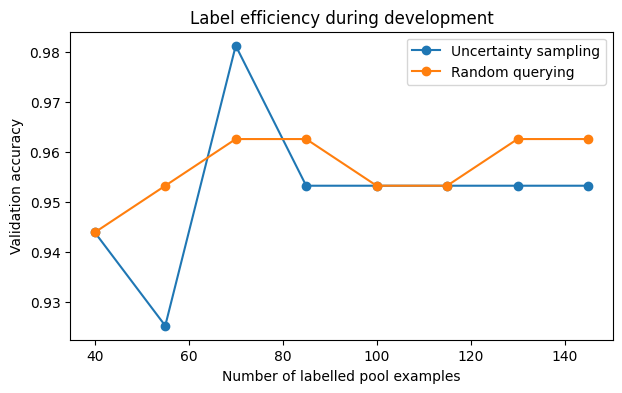

In [15]:

plt.figure(figsize=(7, 4))

plt.plot(
    label_counts,
    active_scores,
    marker="o",
    label="Uncertainty sampling",
)

plt.plot(
    label_counts,
    random_scores,
    marker="o",
    label="Random querying",
)

plt.xlabel("Number of labelled pool examples")
plt.ylabel("Validation accuracy")
plt.title("Label efficiency during development")
plt.legend()
plt.tight_layout
plt.show()


### Label Efficiency During Development

The line graph compares uncertainty sampling and random querying using validation accuracy at different labelled-data budgets.

Uncertainty sampling achieved its highest validation accuracy of **98.1% with 70 labelled examples**, indicating that selecting the most uncertain samples can improve model performance with fewer labels. However, accuracy subsequently decreased to 95.3% and remained at that level for the rest of the experiment.

Random querying showed relatively consistent performance, reaching 96.3% at 70 and 85 labelled examples. Although its accuracy decreased slightly to 95.3% at 100 and 115 examples, it recovered to 96.3% at 130 and 145 examples.

Overall, uncertainty sampling achieved the highest individual validation accuracy, while random querying performed better during the later rounds. These results suggest that uncertainty sampling can be label-efficient, but its advantage was not consistent across all rounds. The experiment also demonstrates that adding more labelled samples does not necessarily improve validation accuracy at every stage.


In [16]:
# Train final models using all labelled examples from each strategy
active_idx = sorted(active_labeled)
random_idx = sorted(random_labeled)

active_final = make_model().fit(
    X_pool.iloc[active_idx], y_pool[active_idx]
)

random_final = make_model().fit(
    X_pool.iloc[random_idx], y_pool[random_idx]
)

# Evaluate on the sealed test set
active_test_acc = accuracy_score(
    yc_test, active_final.predict(Xc_test)
)

random_test_acc = accuracy_score(
    yc_test, random_final.predict(Xc_test)
)

print("Final test accuracy, uncertainty sampling:",
      round(active_test_acc, 3))

print("Final test accuracy, random querying:",
      round(random_test_acc, 3))

Final test accuracy, uncertainty sampling: 0.972
Final test accuracy, random querying: 0.972


The experiment compared uncertainty sampling with random querying for semi-supervised learning and limited-label classification. Uncertainty sampling achieved a peak validation accuracy of 98.1% with 70 labelled examples, while random querying reached a maximum validation accuracy of 96.3%. However, both strategies achieved the same final test accuracy of 97.2% using 145 labelled examples.

These findings indicate that uncertainty sampling can achieve higher validation accuracy at certain stages, but it did not provide a better final test accuracy than random querying in this experiment. Therefore, the effectiveness of active learning depends on the data and the selection strategy, and a higher validation score does not necessarily translate into better test performance.


In [17]:
# EXERCISE: 10 labelled examples from each class
rng_small = np.random.default_rng(42)
rng_random_small = np.random.default_rng(456)

class0 = np.where(y_pool == 0)[0]
class1 = np.where(y_pool == 1)[0]

initial_small = np.concatenate([
    rng_small.choice(class0, 10, replace=False),
    rng_small.choice(class1, 10, replace=False),
])

active_labeled_10 = set(initial_small.tolist())
random_labeled_10 = set(initial_small.tolist())

query_batch = 15
rounds = 8

label_counts_10 = []
active_scores_10 = []
random_scores_10 = []

for round_no in range(rounds):
    active_idx = sorted(active_labeled_10)
    random_idx = sorted(random_labeled_10)

    # Train both models on their currently labelled examples
    active_model = make_model().fit(
        X_pool.iloc[active_idx], y_pool[active_idx]
    )
    random_model = make_model().fit(
        X_pool.iloc[random_idx], y_pool[random_idx]
    )

    # Evaluate on validation data only
    active_acc = accuracy_score(
        y_val, active_model.predict(X_val)
    )
    random_acc = accuracy_score(
        y_val, random_model.predict(X_val)
    )

    label_counts_10.append(len(active_labeled_10))
    active_scores_10.append(active_acc)
    random_scores_10.append(random_acc)

    print(
        f"Round {round_no + 1}: "
        f"labels={len(active_labeled_10):3d} | "
        f"uncertainty={active_acc:.3f} | "
        f"random={random_acc:.3f}"
    )

    if round_no == rounds - 1:
        break

    # Uncertainty sampling: query the 15 most uncertain examples
    unlabeled_active = np.array([
        i for i in range(len(X_pool))
        if i not in active_labeled_10
    ])

    probabilities = active_model.predict_proba(
        X_pool.iloc[unlabeled_active]
    )[:, 1]

    uncertainty = np.abs(probabilities - 0.5)

    selected_active = unlabeled_active[
        np.argsort(uncertainty)[:query_batch]
    ]
    active_labeled_10.update(selected_active.tolist())

    # Random querying: select 15 examples randomly
    unlabeled_random = np.array([
        i for i in range(len(X_pool))
        if i not in random_labeled_10
    ])

    selected_random = rng_random_small.choice(
        unlabeled_random, query_batch, replace=False
    )
    random_labeled_10.update(selected_random.tolist())

Round 1: labels= 20 | uncertainty=0.935 | random=0.935
Round 2: labels= 35 | uncertainty=0.944 | random=0.944
Round 3: labels= 50 | uncertainty=0.963 | random=0.963
Round 4: labels= 65 | uncertainty=0.953 | random=0.963
Round 5: labels= 80 | uncertainty=0.953 | random=0.963
Round 6: labels= 95 | uncertainty=0.953 | random=0.963
Round 7: labels=110 | uncertainty=0.953 | random=0.963
Round 8: labels=125 | uncertainty=0.953 | random=0.963


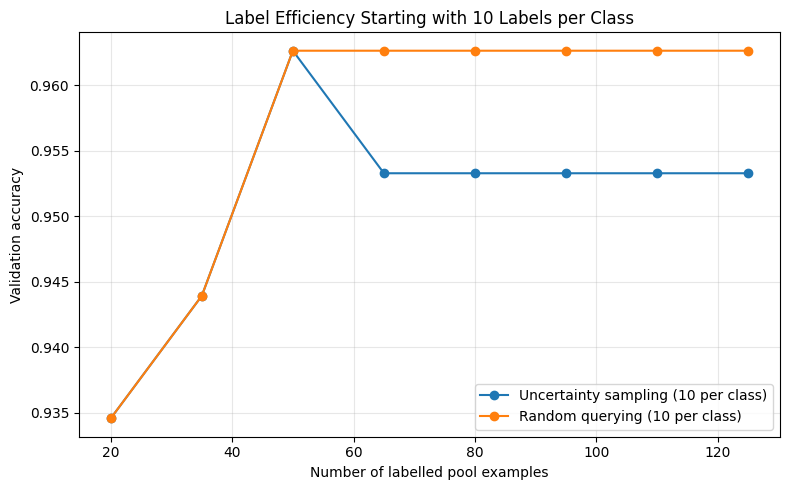

In [18]:
plt.figure(figsize=(8, 5))

plt.plot(
    label_counts_10, active_scores_10,
    marker="o", label="Uncertainty sampling (10 per class)"
)
plt.plot(
    label_counts_10, random_scores_10,
    marker="o", label="Random querying (10 per class)"
)

plt.xlabel("Number of labelled pool examples")
plt.ylabel("Validation accuracy")
plt.title("Label Efficiency Starting with 10 Labels per Class")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Label Efficiency Starting with 10 Labels per Class

The line graph compares uncertainty sampling and random querying when both strategies start with 10 labelled examples from each class, giving an initial total of 20 labelled examples.

Both strategies achieved the same validation accuracy throughout the first three rounds, increasing from 93.5% with 20 labelled examples to 96.3% with 50 labelled examples. This indicates that both approaches performed similarly during the early stages of the experiment.

After 50 labelled examples, random querying maintained a validation accuracy of 96.3% throughout the remaining rounds. In contrast, uncertainty sampling decreased to 95.3% at 65 labelled examples and remained at that level until the final round with 125 labelled examples.

Overall, random querying performed better than uncertainty sampling in the later rounds of this experiment. Although uncertainty sampling prioritises examples close to the model's decision boundary, this strategy did not consistently improve classification performance. The results demonstrate that active learning is not always more effective than random sampling, highlighting the importance of evaluating both approaches against the same baseline.
